In [18]:
from scripts.read_field import read_dir, draw_field, animate_field
from scripts.mm.experiment import Experiment
import os 
import numpy as np 
from typing import Literal
from scripts.scientific import apply
import matplotlib.pyplot as plt
import h5py
from tqdm import tqdm 
    
apply()

In [9]:
# path = os.path.join("./01-repulsion/skyrmion_system")
# runs = sorted([os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-")])[5:]
path = os.path.join("./02-attraction/skyrmion_system")
frame = [3,4]
runs = sorted([os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-")])[frame[0]:frame[1] + 1]
# path = os.path.join("./old")
# runs = sorted([os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-78")])
data = [read_dir(run) for run in runs]
experiments = [Experiment.load(run) for run in runs]

In [2]:
def compress(file: str, data, level: int = 1):
    with h5py.File(file, "w") as f:
        if level == 1:
            scale = (2 ** 7 - 1)
            f.create_dataset(
                "m",
                data=(data * scale + 0.5).astype(np.int8),
                compression=5
            )
        elif level == 2:
            scale = (2 ** 15 - 1)
            f.create_dataset(
                "m",
                data=(data * scale + 0.5).astype(np.int16),
                compression=9
            )
        
def decompress(file: str, level: int = 1):
    with h5py.File(file, "r") as f:
        q = f["m"][:]
        d = (q.astype(np.float64) - 0.5) / f.attrs.get("scale", (2 ** (8 * level - 1) - 1))
        d = d / np.linalg.norm(d, 2, axis=3)[:,:,:,None]
        return d 

In [3]:

def compress_spherical(file: str, m: np.ndarray, bits: int = 8):
    """
    m: array of shape (1, H, W, 3), assumed ~unit vectors
    bits: number of bits per angle (e.g., 8 or 16)
    """

    assert m.shape[-1] == 3

    # Normalize to be safe
    norm = np.linalg.norm(m, axis=-1, keepdims=True)
    m = m / np.clip(norm, 1e-12, None)

    mx, my, mz = m[..., 0], m[..., 1], m[..., 2]

    # Spherical coordinates
    theta = np.arccos(np.clip(mz, -1.0, 1.0))          # [0, pi]
    phi = np.arctan2(my, mx)                           # [-pi, pi]

    levels = 2**bits - 1

    # Quantize
    theta_q = np.round(theta / np.pi * levels).astype(np.uint16)
    phi_q   = np.round((phi + np.pi) / (2*np.pi) * levels).astype(np.uint16)

    dtype = np.uint8 if bits <= 8 else np.uint16

    with h5py.File(file, "w") as f:
        f.create_dataset("theta", data=theta_q.astype(dtype), compression=4)
        f.create_dataset("phi",   data=phi_q.astype(dtype),   compression=4)

        f.attrs["bits"] = bits
        f.attrs["encoding"] = "spherical"

def decompress_spherical(file: str) -> np.ndarray:
    with h5py.File(file, "r") as f:
        theta_q = f["theta"][:]
        phi_q   = f["phi"][:]

        bits = int(f.attrs["bits"])
        levels = 2**bits - 1

    # Dequantize
    theta = theta_q.astype(np.float64) / levels * np.pi
    phi   = phi_q.astype(np.float64)   / levels * 2*np.pi - np.pi

    # Back to Cartesian
    sin_theta = np.sin(theta)

    mx = sin_theta * np.cos(phi)
    my = sin_theta * np.sin(phi)
    mz = np.cos(theta)

    m = np.stack([mx, my, mz], axis=-1)

    return m

In [4]:
import numpy as np
import h5py

def compress_spherical_res(file: str, m: np.ndarray):
    """
    Correct hierarchical spherical compression:
    8-bit coarse θ, φ + 4-bit true residual refinement (properly scaled)
    """

    assert m.shape[-1] == 3

    # --- normalize ---
    norm = np.linalg.norm(m, axis=-1, keepdims=True)
    m = m / np.clip(norm, 1e-12, None)

    mx, my, mz = m[..., 0], m[..., 1], m[..., 2]

    # --- spherical coords ---
    theta = np.arccos(np.clip(mz, -1.0, 1.0))   # [0, π]
    phi   = np.arctan2(my, mx)                  # [-π, π]

    # =========================
    # 1. COARSE QUANTIZATION
    # =========================
    Lc = 255.0

    theta_c = np.round(theta / np.pi * Lc).astype(np.uint8)
    phi_c   = np.round((phi + np.pi) / (2*np.pi) * Lc).astype(np.uint8)

    # reconstruct coarse
    theta_q = theta_c / Lc * np.pi
    phi_q   = phi_c   / Lc * 2*np.pi - np.pi

    # =========================
    # 2. TRUE CONTINUOUS RESIDUAL
    # =========================
    dtheta = theta - theta_q
    dphi   = phi   - phi_q

    # --- correct dynamic ranges ---
    # residuals live in [-step/2, step/2] approximately
    theta_step = np.pi / Lc
    phi_step   = 2*np.pi / Lc

    # normalize to [-1, 1]
    rtheta = np.clip(dtheta / (theta_step / 2), -1, 1)
    rphi   = np.clip(dphi   / (phi_step   / 2), -1, 1)

    # =========================
    # 3. 4-bit quantization
    # =========================
    Lr = 15  # 4-bit unsigned range

    rt = np.round((rtheta + 1) * 0.5 * Lr).astype(np.uint8)
    rp = np.round((rphi   + 1) * 0.5 * Lr).astype(np.uint8)

    # pack residual
    residual = (rt << 4) | rp

    # =========================
    # STORE
    # =========================
    packed = np.stack([theta_c, phi_c, residual], axis=-1)

    with h5py.File(file, "w") as f:
        f.create_dataset("m", data=packed, compression=5)
        f.attrs["format"] = "spherical_8bit_plus_proper_4bit_residual"

In [5]:
def decompress_spherical_res(file: str) -> np.ndarray:
    """
    Correct reconstruction of hierarchical spherical codec.
    """

    with h5py.File(file, "r") as f:
        packed = f["m"][:]

    theta_c = packed[..., 0].astype(np.float64)
    phi_c   = packed[..., 1].astype(np.float64)
    residual = packed[..., 2]

    Lc = 255.0

    # --- coarse reconstruction ---
    theta = theta_c / Lc * np.pi
    phi   = phi_c   / Lc * 2*np.pi - np.pi

    # --- unpack residual ---
    rt = (residual >> 4).astype(np.float64)
    rp = (residual & 0x0F).astype(np.float64)

    Lr = 15.0

    rtheta = (rt / Lr) * 2 - 1
    rphi   = (rp / Lr) * 2 - 1

    # --- back-scale to physical units ---
    theta_step = np.pi / Lc
    phi_step   = 2*np.pi / Lc

    theta += rtheta * (theta_step / 2)
    phi   += rphi   * (phi_step   / 2)

    # --- back to Cartesian ---
    sin_t = np.sin(theta)

    mx = sin_t * np.cos(phi)
    my = sin_t * np.sin(phi)
    mz = np.cos(theta)

    m = np.stack([mx, my, mz], axis=-1)

    # optional cleanup
    norm = np.linalg.norm(m, axis=-1, keepdims=True)
    m = m / np.clip(norm, 1e-12, None)

    return m

In [51]:
base = './old/skyrmion_system/_archive'
folders = [f for f in os.listdir(base) if not f.startswith(".") and not f.startswith("_")]
paths = [f"{base}/{f}" for f in folders]

In [52]:
for path in tqdm(paths):
    data = read_dir(path)
    if (data.shape[0] == 0):
        continue
    print(f'Compressing [{path}]...')
    compress_spherical_res(f"{path}/data.h5",data)
    # files = [f for f in os.listdir(path) if f.startswith("skyrmion_system-Oxs_") and f.find('0000000-0000000') == -1]
    # for file in files:
    #     os.remove(f"{path}/{file}")

  0%|          | 0/86 [00:00<?, ?it/s]

Compressing [./old/skyrmion_system/_archive/recorderd-skyrmion-creation,alpha=5]...


  6%|▌         | 5/86 [00:05<01:25,  1.06s/it]

Compressing [./old/skyrmion_system/_archive/drive-30]...


  9%|▉         | 8/86 [00:08<01:27,  1.13s/it]

Compressing [./old/skyrmion_system/_archive/drive-50-first-skyrmion-creation-time-driver]...
Compressing [./old/skyrmion_system/_archive/drive-31]...


... (39 outputs left out)

Compressing [./old/skyrmion_system/_archive/drive-4]...


 92%|█████████▏| 79/86 [01:07<00:10,  1.57s/it]

Compressing [./old/skyrmion_system/_archive/drive-5]...


100%|██████████| 86/86 [01:12<00:00,  1.18it/s]


In [53]:
for path in tqdm(paths):
    data = read_dir(path)
    if (data.shape[0] == 0):
        continue
    print(f'Deleting [{path}]...')
    files = [f for f in os.listdir(path) if f.startswith("skyrmion_system-Oxs_") and f.find('0000000-0000000') == -1]
    for file in files:
        os.remove(f"{path}/{file}")

  6%|▌         | 5/86 [00:01<00:23,  3.46it/s]

Deleting [./old/skyrmion_system/_archive/recorderd-skyrmion-creation,alpha=5]...


  9%|▉         | 8/86 [00:02<00:22,  3.46it/s]

Deleting [./old/skyrmion_system/_archive/drive-30]...
Deleting [./old/skyrmion_system/_archive/drive-50-first-skyrmion-creation-time-driver]...


 14%|█▍        | 12/86 [00:03<00:21,  3.46it/s]

Deleting [./old/skyrmion_system/_archive/drive-31]...
Deleting [./old/skyrmion_system/_archive/drive-47]...


... (32 outputs left out)

 92%|█████████▏| 79/86 [00:16<00:02,  2.77it/s]

Deleting [./old/skyrmion_system/_archive/drive-4]...


100%|██████████| 86/86 [00:17<00:00,  4.99it/s]

Deleting [./old/skyrmion_system/_archive/drive-5]...


1.7576417169016618 0.002% 0.041%


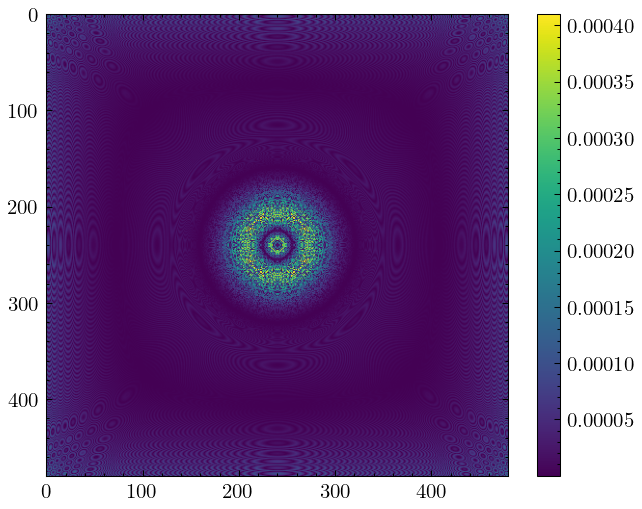

In [40]:
d = decompress_spherical_res(f"{paths[0]}/data.h5")
frame = 1
# # diff = np.linalg.norm(d[frame,:,:,:]-data[0][frame,:,:,:], axis=2) / 3
diff = np.abs(d[frame,:,:,2]-data[frame,:,:,2] * 1e5)
plt.imshow(diff)
print(np.sum(diff) / 3, "{:.3f}%".format(np.mean(diff) * 100), "{:.3f}%".format(np.max(diff) * 100))
plt.colorbar()

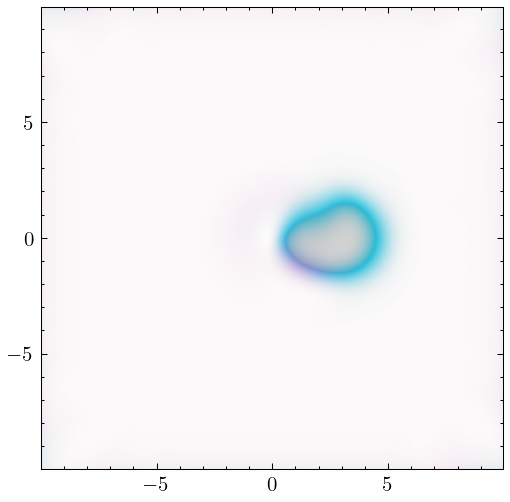

In [24]:
fig, ax = plt.subplots()
draw_field(ax, d[3], 'spirality', cutoff=1)